# Step 4: Exploring day patterns with PCA

**Project:** Learning What "Normal" Looks Like: Clustering-Based Contextual Anomaly Detection in Bike Sharing

Each day is now a 24-value shape (Step 3). Principal Component Analysis (PCA; Anomaly Detection 2, Slides 17 to 22) finds the few directions in which these shapes differ most. This notebook answers four questions:

1. How many components are needed to describe the day shapes?
2. What does each component *mean* as a pattern over the day?
3. Which day attributes (working day, temperature, bad weather, casual share) line up with each component?
4. Do casual and registered riders vary in the same way?

This covers task 3 of the assignment (dimension reduction and visualization), and the result decides how many dimensions the clustering in Step 5 uses.

**Inputs:** `shape_all.csv`, `shape_casual.csv`, `shape_registered.csv`, `day_info.csv`, `level.csv` (Steps 2 and 3).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
})

GROUPS = ["all", "casual", "registered"]
shape = {g: pd.read_csv(f"shape_{g}.csv", index_col="dteday", parse_dates=True) for g in GROUPS}
info = pd.read_csv("day_info.csv", index_col="dteday", parse_dates=True)
level = pd.read_csv("level.csv", index_col="dteday", parse_dates=True)
hours = np.arange(24)

## 1. How many components?

PCA is fitted on the shapes of each rider group. The shapes are already on one common scale (shares of the day, summing to 1), so they are only centred, not standardised: standardising would give quiet night hours the same weight as rush hours.

The cumulative explained variance shows how much of the day-to-day variation the first *k* components capture.

In [2]:
pca = {g: PCA().fit(shape[g].values) for g in GROUPS}

# The sign of a component is arbitrary. Fix it so that a positive score on PC1 means
# "more rush-hour riding" for every group, which makes the plots comparable.
rush = [7, 8, 17, 18]
for g in GROUPS:
    if pca[g].components_[0][rush].sum() < 0:
        pca[g].components_[0] *= -1

def components_for(g, share):
    return int(np.argmax(np.cumsum(pca[g].explained_variance_ratio_) >= share) + 1)

summary = pd.DataFrame({
    g: {"PC1": pca[g].explained_variance_ratio_[0],
        "PC1 + PC2": pca[g].explained_variance_ratio_[:2].sum(),
        "components for 80%": components_for(g, 0.80),
        "components for 90%": components_for(g, 0.90)}
    for g in GROUPS}).T
summary.style.format({"PC1": "{:.0%}", "PC1 + PC2": "{:.0%}",
                      "components for 80%": "{:.0f}", "components for 90%": "{:.0f}"})

,PC1,PC1 + PC2,components for 80%,components for 90%
all,70%,83%,2,4
casual,40%,55%,8,12
registered,71%,84%,2,4


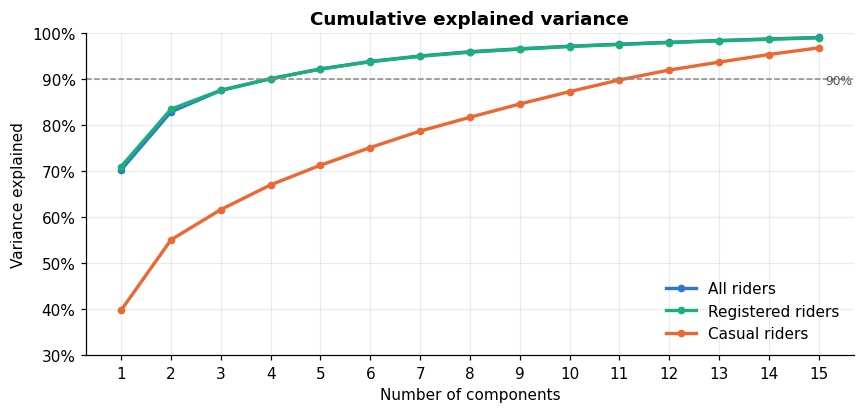

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.8))
colors = {"all": BLUE, "registered": AQUA, "casual": ORANGE}
for g in ["all", "registered", "casual"]:
    cum = np.cumsum(pca[g].explained_variance_ratio_)[:15]
    ax.plot(range(1, 16), cum, color=colors[g], linewidth=2.2, marker="o", markersize=4,
            label=f"{g.capitalize()} riders")
ax.axhline(0.9, color=GREY, linewidth=1, linestyle="--")
ax.annotate("90%", (15, 0.9), xytext=(4, -3), textcoords="offset points", color="#52514e", fontsize=8)
ax.set(title="Cumulative explained variance", xlabel="Number of components",
       ylabel="Variance explained", xticks=range(1, 16), ylim=(0.3, 1.0))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.legend(frameon=False, loc="lower right")
plt.show()

**Result.**

- **All riders and registered riders:** one component already explains about 70% of the variation, and 4 components explain 90%. Their days follow very regular patterns.
- **Casual riders:** the first component explains only about 40%, and about 12 components are needed for 90%. Casual days are far less regular: no single pattern describes most of them.

The curves for all and registered riders nearly coincide because registered riders make up about 80% of all rentals.

## 2. What each component means

A component is a list of 24 weights, one per hour, so it can be drawn as a curve. The easiest way to read it is to start from the **average day** and move along the component: the plot shows the average shape, and the shape of a day that scores high (+2 standard deviations) or low (-2 standard deviations) on that component.

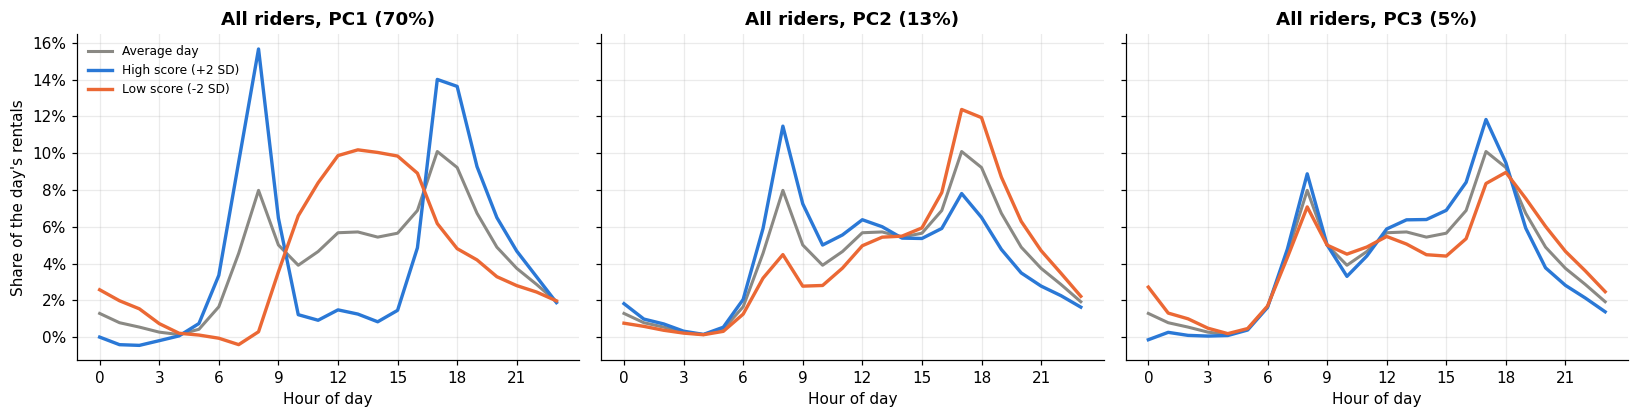

In [4]:
def plot_component(ax, g, k, title):
    p = pca[g]
    mean = p.mean_
    step = 2 * np.sqrt(p.explained_variance_[k])
    ax.plot(hours, mean, color=GREY, linewidth=2, label="Average day")
    ax.plot(hours, mean + step * p.components_[k], color=BLUE, linewidth=2.2, label="High score (+2 SD)")
    ax.plot(hours, mean - step * p.components_[k], color=ORANGE, linewidth=2.2, label="Low score (-2 SD)")
    ax.set(title=title, xlabel="Hour of day", xticks=range(0, 24, 3))
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.9), sharey=True)
for k, ax in enumerate(axes):
    share = pca["all"].explained_variance_ratio_[k]
    plot_component(ax, "all", k, f"All riders, PC{k + 1} ({share:.0%})")
axes[0].set_ylabel("Share of the day's rentals")
axes[0].legend(frameon=False, loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

**Reading the three components (all riders).**

- **PC1, commuting versus midday riding (about 70%).** A high score means sharp peaks at 8:00 and 17:00 to 18:00; a low score means one broad block in the early afternoon. This is the difference between a working day and a day off.
- **PC2, morning versus evening balance (about 13%).** A high score means relatively more riding in the morning peak; a low score means more in the evening peak.
- **PC3, afternoon versus late evening (about 5%).** A high score means riding concentrated in the afternoon; a low score means more riding after 20:00.

The curves dip slightly below 0% at a few night hours. This is not a real negative number of rentals: PCA describes shapes as straight-line combinations, and two standard deviations along a component can overshoot the range of real days. The direction of the change is what matters.

The next section checks which day attributes go with each component, to see whether these interpretations hold.

## 3. Which day attributes line up with each component?

The score of each day on each component is correlated with attributes from `day_info.csv` and `level.csv`. These attributes were **not** used to build the components, so a strong correlation is a genuine finding about the data.

In [5]:
scores = {g: pd.DataFrame(pca[g].transform(shape[g].values)[:, :12], index=shape[g].index,
                          columns=[f"PC{k + 1}" for k in range(12)]) for g in GROUPS}

attributes = pd.DataFrame({
    "working day": info.workingday,
    "mean temperature (°C)": info.temp_c_mean,
    "bad-weather daytime hours": info.bad_weather_daytime_hours,
    "casual share": info.casual_share,
    "level (all riders)": level.level_all,
})
corr = pd.DataFrame({pc: attributes.corrwith(scores["all"][pc]) for pc in ["PC1", "PC2", "PC3"]})
corr.round(2).style.background_gradient(cmap="RdBu_r", vmin=-1, vmax=1).format("{:.2f}")

,PC1,PC2,PC3
working day,0.93,0.05,0.12
mean temperature (°C),0.09,-0.27,-0.36
bad-weather daytime hours,0.08,0.20,-0.36
casual share,-0.73,-0.19,-0.08
level (all riders),0.02,-0.16,0.38


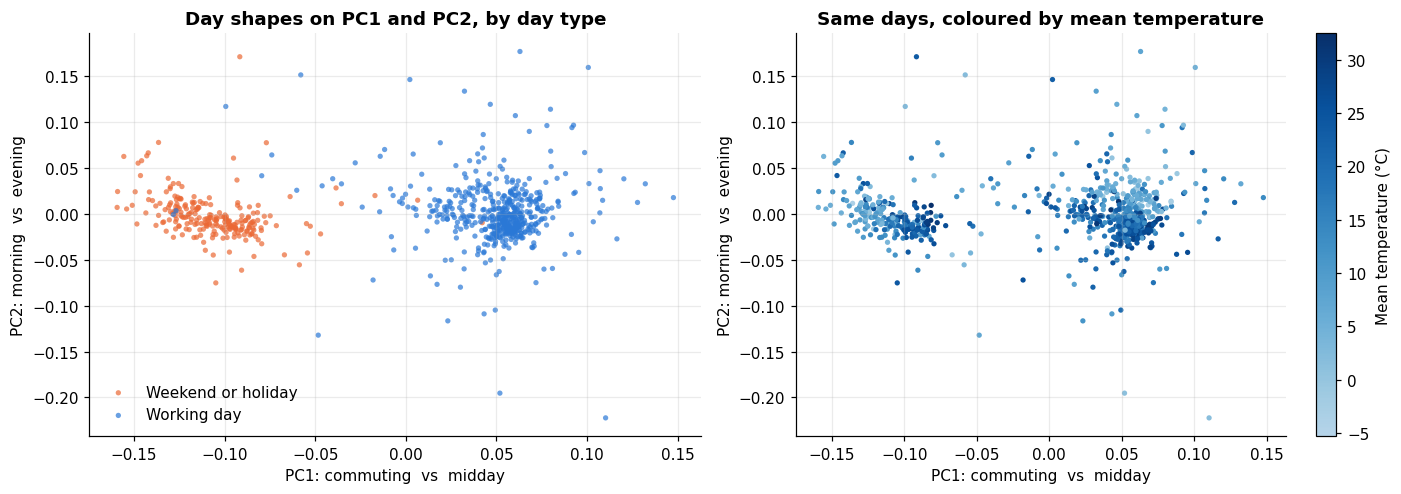

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
s = scores["all"]
work = info.workingday == 1
axes[0].scatter(s.PC1[~work], s.PC2[~work], s=12, color=ORANGE, alpha=0.7, edgecolors="none",
                label="Weekend or holiday")
axes[0].scatter(s.PC1[work], s.PC2[work], s=12, color=BLUE, alpha=0.7, edgecolors="none",
                label="Working day")
axes[0].set(title="Day shapes on PC1 and PC2, by day type", xlabel="PC1: commuting  vs  midday",
            ylabel="PC2: morning  vs  evening")
axes[0].legend(frameon=False, loc="lower left")

# Start the colour scale at a mid blue so the coldest days stay visible on white.
temp_cmap = plt.matplotlib.colors.ListedColormap(plt.cm.Blues(np.linspace(0.3, 1, 256)))
sc = axes[1].scatter(s.PC1, s.PC2, c=info.temp_c_mean, cmap=temp_cmap, s=12, edgecolors="none")
axes[1].set(title="Same days, coloured by mean temperature", xlabel="PC1: commuting  vs  midday",
            ylabel="PC2: morning  vs  evening")
fig.colorbar(sc, ax=axes[1], label="Mean temperature (°C)")
fig.tight_layout()
plt.show()

**Result.**

- **PC1 is almost exactly the working-day label** (correlation about 0.93), and it is strongly negative with the casual share: days off have midday shapes and more casual riders.
- **PC2 and PC3 relate to temperature and weather**, not to the calendar: on cold days, relatively more of the riding happens in the morning peak (PC2), and on warm days, as well as on days with daytime rain or snow, relatively more of it happens late in the evening (PC3). The correlations are moderate (around 0.3), so weather shifts the shape but does not define it.
- The scatter plot shows **two dense groups** (working days and days off) and a scattering of days far from both. Those scattered days are what the anomaly detectors in Step 6 are meant to find. They are not looked up here, to keep the evaluation fair.

So the calendar explains the biggest difference between days, but not all of it. The clustering in Step 5 can test whether more than two day types exist once the weather-related components are included.

## 4. Casual versus registered riders

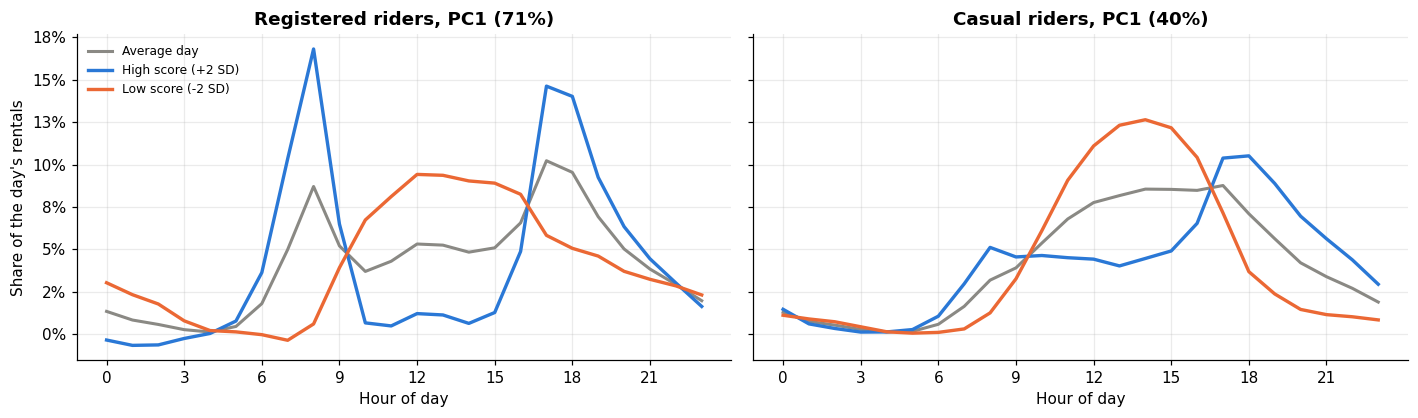

,registered: PC1,casual: PC1
working day,0.94,0.64
mean temperature (°C),0.11,0.47
bad-weather daytime hours,0.05,0.13
casual share,-0.71,-0.37


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.9), sharey=True)
for ax, g in zip(axes, ["registered", "casual"]):
    share = pca[g].explained_variance_ratio_[0]
    plot_component(ax, g, 0, f"{g.capitalize()} riders, PC1 ({share:.0%})")
axes[0].set_ylabel("Share of the day's rentals")
axes[0].legend(frameon=False, loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

rows = {}
for g in ["registered", "casual"]:
    rows[g] = attributes.drop(columns="level (all riders)").corrwith(scores[g]["PC1"])
pd.DataFrame(rows).round(2).rename(columns=lambda g: f"{g}: PC1")

**Result.**

- **Registered riders' main component is commuting versus midday**, the same as for all riders, and it matches the working-day label almost perfectly.
- **Casual riders' main component is different:** it contrasts midday with evening riding, and it relates to *both* the working day and temperature (cold days push casual riding into the middle of the day). It also explains much less of the variation.

This is the clearest evidence so far for the second research question. The two groups do not just ride at different amounts; they ride in **different ways** and respond to **different conditions**. Anomalies may therefore look different for each group.

## 5. Save the PCA scores

The scores are saved for Step 5. The number of components kept for clustering follows Section 1: the smallest number that explains at least 90% of the variance in each group.

In [8]:
keep = {g: components_for(g, 0.90) for g in GROUPS}
for g in GROUPS:
    z = pd.DataFrame(pca[g].transform(shape[g].values)[:, :keep[g]], index=shape[g].index,
                     columns=[f"PC{k + 1}" for k in range(keep[g])])
    z.to_csv(f"pca_scores_{g}.csv")
print("Components kept (90% variance):", keep)
print("Saved pca_scores_all.csv, pca_scores_casual.csv, pca_scores_registered.csv")

Components kept (90% variance): {'all': 4, 'casual': 12, 'registered': 4}
Saved pca_scores_all.csv, pca_scores_casual.csv, pca_scores_registered.csv


## Summary for the report

- For all riders, **4 principal components explain 90%** of the variation in day shapes; the first explains about 70% on its own.
- **PC1 is commuting versus midday riding** and matches the working-day label (correlation about 0.93). PC2 (morning versus evening) and PC3 (afternoon versus late evening) are linked to temperature and bad weather instead of the calendar.
- **Casual riders are far less regular:** their first component explains only about 40%, and about 12 components are needed for 90%. Their main pattern (midday versus evening) depends on both day type and temperature.
- The PCA scatter shows two dense groups of days and a set of outlying days, which motivates clustering (Step 5) and anomaly scoring (Step 6).

**Next, Step 5:** cluster the PCA scores into day types (k-means, hierarchical, GMM, DBSCAN) and choose the number of clusters.